<a href="https://colab.research.google.com/github/AnisaIntania/Natural-Language-Processing/blob/main/Sesi_Lab_6_Anisa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, SimpleRNN, LSTM, GRU, Dropout
from tensorflow.keras.callbacks import EarlyStopping

import time

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)

TensorFlow version: 2.21.0
NumPy version: 2.1.3


In [ ]:
import tensorflow as tf
print("GPU tersedia:", tf.config.list_physical_devices('GPU'))

GPU tersedia: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import pandas as pd
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv"
df = pd.read_csv(url)
print("Ukuran dataset:", df.shape)
display(df.head())

Ukuran dataset: (3650, 2)


,Date,Temp
0,1981-01-01,20.7
1,1981-01-02,17.9
2,1981-01-03,18.8
3,1981-01-04,14.6
4,1981-01-05,15.8


In [ ]:
print("Informasi dataset:")
df.info()

print("\nJumlah missing value:")
print(df.isnull().sum())

print("\nJumlah data duplikat:", df.duplicated().sum())

print("\nStatistik data:")
display(df.describe())

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3650 entries, 0 to 3649
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    3650 non-null   object 
 1   Temp    3650 non-null   float64
dtypes: float64(1), object(1)
memory usage: 57.2+ KB

Jumlah missing value:
Date    0
Temp    0
dtype: int64

Jumlah data duplikat: 0

Statistik data:


,Temp
count,3650.000000
mean,11.177753
std,4.071837
min,0.000000
25%,8.300000
50%,11.000000
75%,14.000000
max,26.300000


In [ ]:
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

print(df.dtypes)
display(df.head())

Date    datetime64[ns]
Temp           float64
dtype: object


,Date,Temp
0,1981-01-01,20.7
1,1981-01-02,17.9
2,1981-01-03,18.8
3,1981-01-04,14.6
4,1981-01-05,15.8


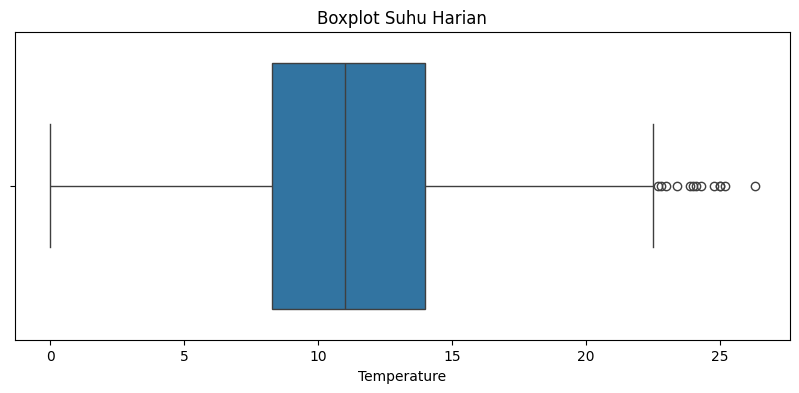

In [ ]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df["Temp"])
plt.title("Boxplot Suhu Harian")
plt.xlabel("Temperature")
plt.show()

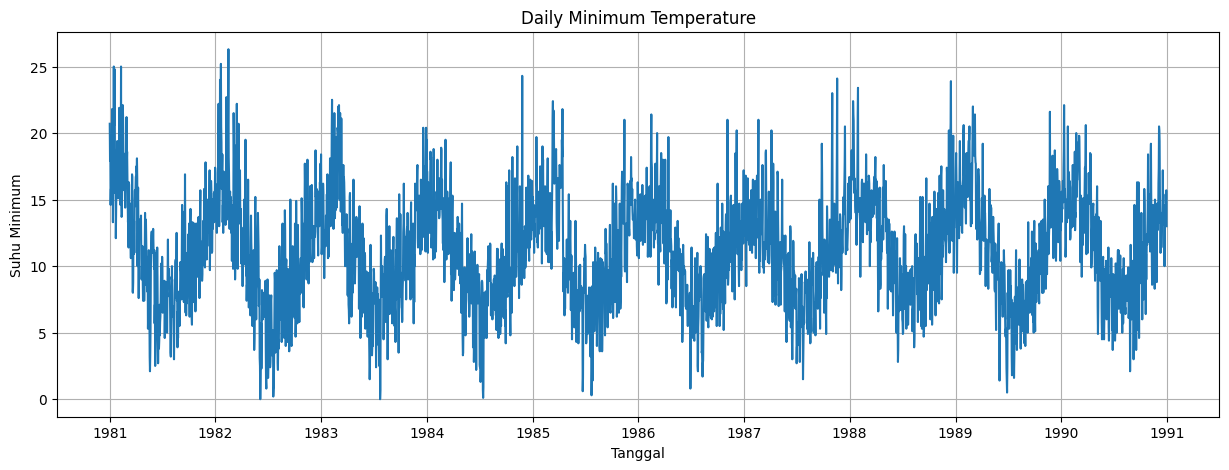

In [ ]:
plt.figure(figsize=(15, 5))

plt.plot(df["Date"], df["Temp"])
plt.title("Daily Minimum Temperature")
plt.xlabel("Tanggal")
plt.ylabel("Suhu Minimum")
plt.grid(True)

plt.show()

In [ ]:
#split data
n = len(df)

train_end = int(n * 0.70)
val_end = int(n * 0.80)

train_df = df.iloc[:train_end]
val_df = df.iloc[train_end:val_end]
test_df = df.iloc[val_end:]

print("Total data :", len(df))
print("Train     :", len(train_df))
print("Validation:", len(val_df))
print("Test      :", len(test_df))

print("\nTanggal Train:")
print(train_df["Date"].min(), "sampai", train_df["Date"].max())

print("\nTanggal Validation:")
print(val_df["Date"].min(), "sampai", val_df["Date"].max())

print("\nTanggal Test:")
print(test_df["Date"].min(), "sampai", test_df["Date"].max())

Total data : 3650
Train     : 2555
Validation: 365
Test      : 730

Tanggal Train:
1981-01-01 00:00:00 sampai 1987-12-31 00:00:00

Tanggal Validation:
1988-01-01 00:00:00 sampai 1988-12-30 00:00:00

Tanggal Test:
1989-01-01 00:00:00 sampai 1990-12-31 00:00:00


In [ ]:
#k-fold cross validation
from sklearn.model_selection import KFold
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
print("K-Fold Cross Validation (5 Fold)")
for fold, (train_index, val_index) in enumerate(
    kf.split(train_df), 1
):
    print(f"\nFold {fold}")
    print("Jumlah data training   :", len(train_index))
    print("Jumlah data validation :", len(val_index))

K-Fold Cross Validation (5 Fold)

Fold 1
Jumlah data training   : 2044
Jumlah data validation : 511

Fold 2
Jumlah data training   : 2044
Jumlah data validation : 511

Fold 3
Jumlah data training   : 2044
Jumlah data validation : 511

Fold 4
Jumlah data training   : 2044
Jumlah data validation : 511

Fold 5
Jumlah data training   : 2044
Jumlah data validation : 511


In [ ]:
#scalling
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train_df[["Temp"]])
val_scaled = scaler.transform(val_df[["Temp"]])
test_scaled = scaler.transform(test_df[["Temp"]])

print("Data train setelah scaling:")
print(train_scaled[:5])

Data train setelah scaling:
[[0.78707224]
 [0.68060837]
 [0.7148289 ]
 [0.55513308]
 [0.60076046]]


In [ ]:
#membuat squence
WINDOW = 14

def create_sequences(data, window):
    X = []
    y = []

    for i in range(window, len(data)):
        X.append(data[i-window:i])
        y.append(data[i])

    return np.array(X), np.array(y)

In [ ]:
#Membuat data train, validation, test
val_input = np.concatenate([train_scaled[-WINDOW:], val_scaled])
test_input = np.concatenate([val_scaled[-WINDOW:], test_scaled])

X_train, y_train = create_sequences(train_scaled, WINDOW)
X_val, y_val = create_sequences(val_input, WINDOW)
X_test, y_test = create_sequences(test_input, WINDOW)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val  :", X_val.shape)
print("y_val  :", y_val.shape)

print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

X_train: (2541, 14, 1)
y_train: (2541, 1)
X_val  : (365, 14, 1)
y_val  : (365, 1)
X_test : (730, 14, 1)
y_test : (730, 1)


In [ ]:
#fungsi membuat model
def build_model(kind="rnn", units=64, dropout_rate=0.0):
    model = Sequential()
    if kind == "rnn":
        model.add(SimpleRNN(
            units,
            input_shape=(WINDOW, 1)
        ))

    elif kind == "lstm":
        model.add(LSTM(
            units,
            input_shape=(WINDOW, 1)
        ))

    elif kind == "gru":
        model.add(GRU(
            units,
            input_shape=(WINDOW, 1)
        ))

    if dropout_rate > 0:
        model.add(Dropout(dropout_rate))
    model.add(Dense(1))
    model.compile(
        optimizer="adam",
        loss="mse"
    )
    return model

In [ ]:
#training 3 model
models = {}
histories = {}
training_times = {}

for kind in ["rnn", "lstm", "gru"]:
    print("\n" + "="*50)
    print("Training model:", kind.upper())
    print("="*50)
    model = build_model(kind=kind, units=64)
    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    start_time = time.time()
    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=40,
        batch_size=32,
        verbose=1,
        callbacks=[early_stopping]
    )

    end_time = time.time()
    models[kind] = model
    histories[kind] = history
    training_times[kind] = end_time - start_time
    print(f"\nWaktu training {kind.upper()}: "
          f"{training_times[kind]:.2f} detik")


Training model: RNN


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - loss: 0.0362 - val_loss: 0.0130
Epoch 2/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0135 - val_loss: 0.0110
Epoch 3/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0116 - val_loss: 0.0098
Epoch 4/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0107 - val_loss: 0.0096
Epoch 5/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0101 - val_loss: 0.0095
Epoch 6/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0096 - val_loss: 0.0088
Epoch 7/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0092 - val_loss: 0.0086
Epoch 8/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0092 - val_loss: 0.0085
Epoch 9/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0091 - val_loss: 0.0103
Epoch 10/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0092 - val_loss: 0.0085
Epoch 11/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0091 - val_loss: 0.0093
Epoch 12/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0091 - val_l

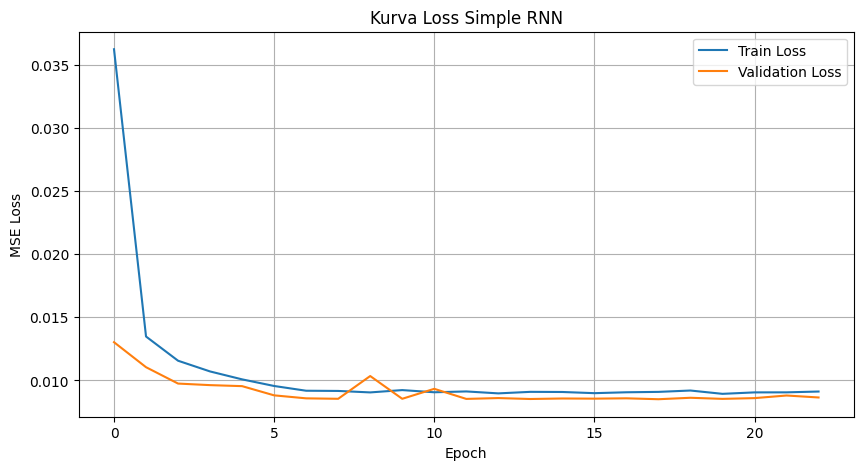

In [ ]:
#Grafik loss RNN
plt.figure(figsize=(10, 5))
plt.plot(
    histories["rnn"].history["loss"],
    label="Train Loss"
)

plt.plot(
    histories["rnn"].history["val_loss"],
    label="Validation Loss"
)

plt.title("Kurva Loss Simple RNN")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.show()

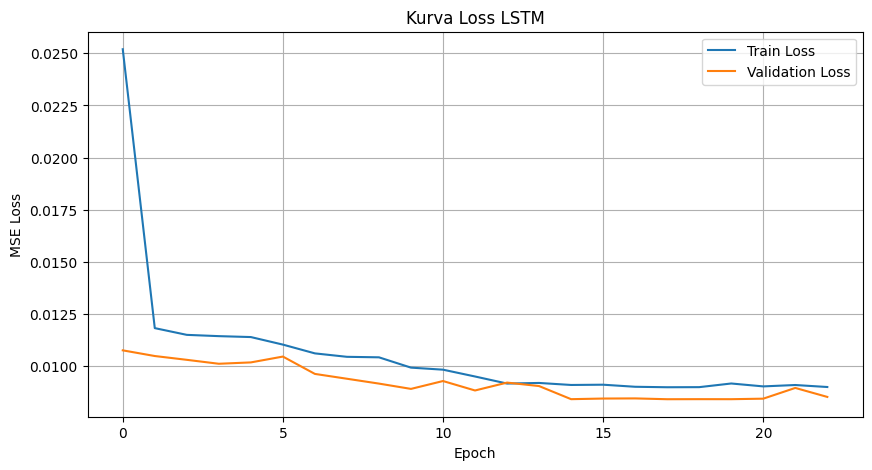

In [ ]:
#grafik loss LSTM
plt.figure(figsize=(10, 5))

plt.plot(
    histories["lstm"].history["loss"],
    label="Train Loss"
)

plt.plot(
    histories["lstm"].history["val_loss"],
    label="Validation Loss"
)

plt.title("Kurva Loss LSTM")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.show()

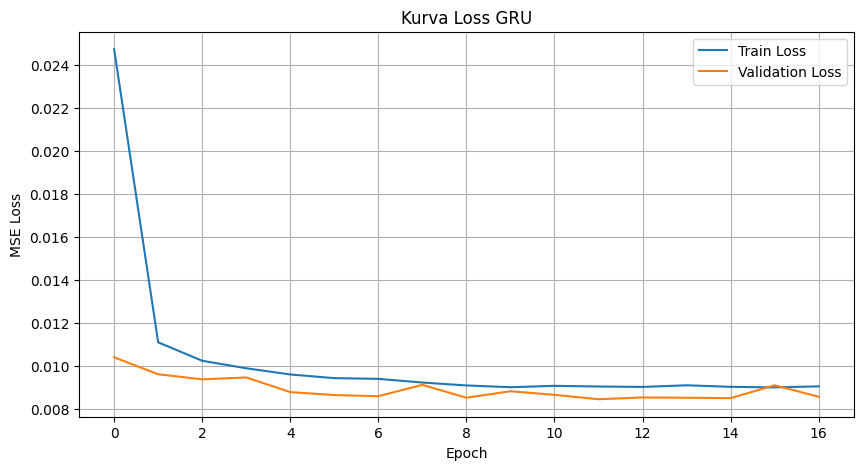

In [ ]:
#grafik loss GRU
plt.figure(figsize=(10, 5))
plt.plot(
    histories["gru"].history["loss"],
    label="Train Loss"
)

plt.plot(
    histories["gru"].history["val_loss"],
    label="Validation Loss"
)

plt.title("Kurva Loss GRU")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
#prediksi 3 model
predictions = {}
for kind, model in models.items():
    pred = model.predict(X_test, verbose=0)
    predictions[kind] = scaler.inverse_transform(pred)
y_test_original = scaler.inverse_transform(y_test)
print("Shape actual:", y_test_original.shape)
for kind in predictions:
    print(f"Shape prediction {kind.upper()}:",
          predictions[kind].shape)

Shape actual: (730, 1)
Shape prediction RNN: (730, 1)
Shape prediction LSTM: (730, 1)
Shape prediction GRU: (730, 1)


In [ ]:
#metrik evaluasi MAE, RMSE, MAPE
results = []
for kind in ["rnn", "lstm", "gru"]:
    y_pred = predictions[kind]
    mae = mean_absolute_error(
        y_test_original,
        y_pred
    )
    rmse = np.sqrt(
        mean_squared_error(
            y_test_original,
            y_pred
        )
    )
    mape = np.mean(
        np.abs(
            (y_test_original - y_pred)
            / y_test_original
        )
    ) * 100
    results.append({
        "Model": kind.upper(),
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape,
        "Training Time (s)": training_times[kind]
    })

results_df = pd.DataFrame(results)
display(results_df)

,Model,MAE,RMSE,MAPE (%),Training Time (s)
0,RNN,1.750901,2.217669,20.962339,14.453095
1,LSTM,1.748357,2.218514,21.376789,14.920063
2,GRU,1.744964,2.214251,21.043332,10.063281


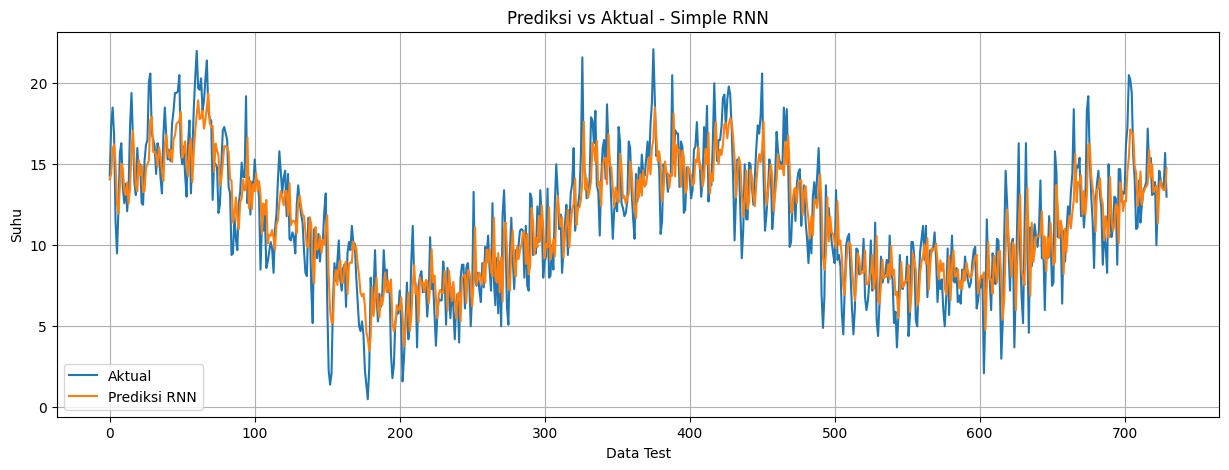

In [ ]:
# prediksi dan aktual RNN
plt.figure(figsize=(15, 5))
plt.plot(
    y_test_original,
    label="Aktual"
)

plt.plot(
    predictions["rnn"],
    label="Prediksi RNN"
)
plt.title("Prediksi vs Aktual - Simple RNN")
plt.xlabel("Data Test")
plt.ylabel("Suhu")
plt.legend()
plt.grid(True)
plt.show()

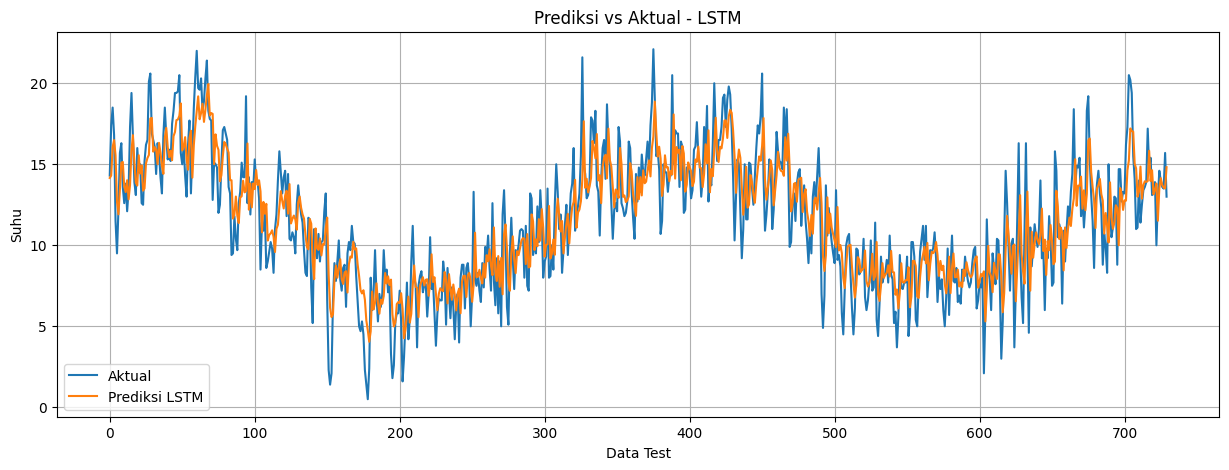

In [ ]:
# prediksi dan aktual LSTM
plt.figure(figsize=(15, 5))
plt.plot(
    y_test_original,
    label="Aktual"
)
plt.plot(
    predictions["lstm"],
    label="Prediksi LSTM"
)
plt.title("Prediksi vs Aktual - LSTM")
plt.xlabel("Data Test")
plt.ylabel("Suhu")
plt.legend()
plt.grid(True)
plt.show()

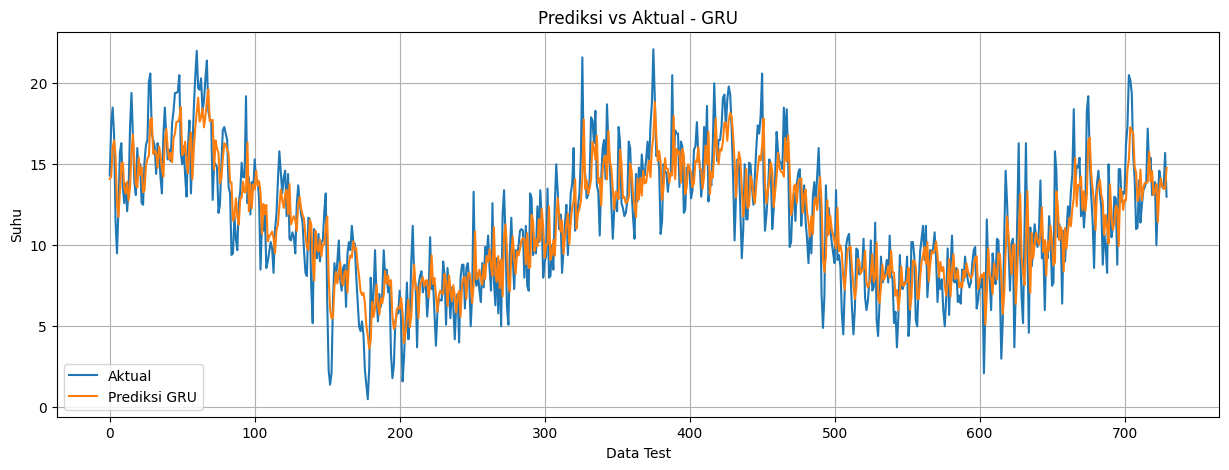

In [ ]:
# prediksi dan aktual GRU
plt.figure(figsize=(15, 5))
plt.plot(
    y_test_original,
    label="Aktual"
)
plt.plot(
    predictions["gru"],
    label="Prediksi GRU"
)
plt.title("Prediksi vs Aktual - GRU")
plt.xlabel("Data Test")
plt.ylabel("Suhu")
plt.legend()
plt.grid(True)
plt.show()

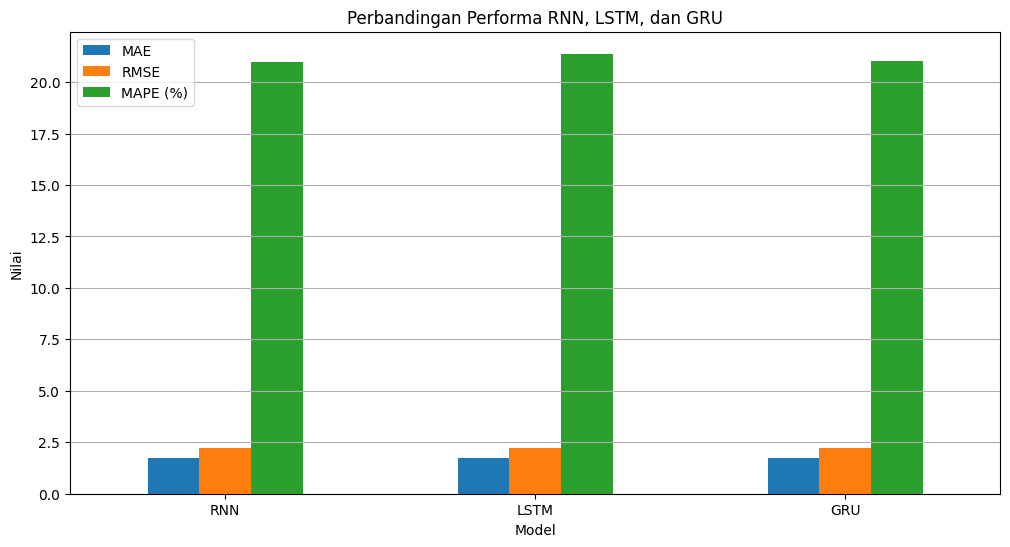

In [ ]:
#visualisasi perbandingan metrik
results_plot = results_df.set_index("Model")[["MAE", "RMSE", "MAPE (%)"]]
results_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Perbandingan Performa RNN, LSTM, dan GRU")
plt.ylabel("Nilai")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

In [ ]:
#Time Series Cross Validation
tscv = TimeSeriesSplit(n_splits=5)
print("Time Series Cross Validation")
for fold, (train_index, val_index) in enumerate(
    tscv.split(train_scaled), 1
):
    print(f"\nFold {fold}")
    print("Train:", len(train_index))
    print("Validation:", len(val_index))

Time Series Cross Validation

Fold 1
Train: 430
Validation: 425

Fold 2
Train: 855
Validation: 425

Fold 3
Train: 1280
Validation: 425

Fold 4
Train: 1705
Validation: 425

Fold 5
Train: 2130
Validation: 425


In [ ]:
#Eksperimen Window Size 7, 14, dan 30
# Eksperimen variasi window size
WINDOW_SIZES = [7, 14, 30]
window_results = []
for window in WINDOW_SIZES:
    print("\n" + "="*60)
    print(f"Eksperimen Window Size: {window} hari")
    print("="*60)

    # Membuat data sequence
    X_train_w, y_train_w = create_sequences(
        train_scaled, window
    )
    val_input_w = np.concatenate([
        train_scaled[-window:],
        val_scaled
    ])
    test_input_w = np.concatenate([
        val_scaled[-window:],
        test_scaled
    ])
    X_val_w, y_val_w = create_sequences(
        val_input_w, window
    )
    X_test_w, y_test_w = create_sequences(
        test_input_w, window
    )
    # Membuat model LSTM
    model = Sequential([
        LSTM(
            64,
            input_shape=(window, 1)
        ),
        Dense(1)
    ])
    model.compile(
        optimizer="adam",
        loss="mse"
    )
    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )
    # Training
    start_time = time.time()
    history = model.fit(
        X_train_w,
        y_train_w,
        validation_data=(X_val_w, y_val_w),
        epochs=40,
        batch_size=32,
        verbose=1,
        callbacks=[early_stopping]
    )
    training_time = time.time() - start_time
    # Prediksi
    y_pred_w = model.predict(
        X_test_w,
        verbose=0
    )
    # Kembalikan ke skala suhu asli
    y_test_original_w = scaler.inverse_transform(
        y_test_w
    )
    y_pred_original_w = scaler.inverse_transform(
        y_pred_w
    )
    # Evaluasi
    mae = mean_absolute_error(
        y_test_original_w,
        y_pred_original_w
    )
    rmse = np.sqrt(
        mean_squared_error(
            y_test_original_w,
            y_pred_original_w
        )
    )
    mape = np.mean(
        np.abs(
            (y_test_original_w - y_pred_original_w)
            / y_test_original_w
        )
    ) * 100
    # Simpan hasil
    window_results.append({
        "Window": window,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape,
        "Training Time (s)": training_time
    })
# Buat tabel hasil
window_results_df = pd.DataFrame(window_results)
display(window_results_df)


Eksperimen Window Size: 7 hari
Epoch 1/40


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0208 - val_loss: 0.0103
Epoch 2/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0113 - val_loss: 0.0103
Epoch 3/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0112 - val_loss: 0.0101
Epoch 4/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0109 - val_loss: 0.0099
Epoch 5/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0109 - val_loss: 0.0099
Epoch 6/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0107 - val_loss: 0.0097
Epoch 7/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0106 - val_loss: 0.0102
Epoch 8/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0105 - val_loss: 0.0095
Epoch 9/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0103 - val_loss: 0.0095
Epoch 10/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0103 - val_loss: 0.0094
Epoch 11/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0101 - val_loss: 0.0093
Epoch 12/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0100 - val_loss: 0.0092


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0226 - val_loss: 0.0110
Epoch 2/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0117 - val_loss: 0.0104
Epoch 3/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0116 - val_loss: 0.0102
Epoch 4/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0113 - val_loss: 0.0106
Epoch 5/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0109 - val_loss: 0.0099
Epoch 6/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0109 - val_loss: 0.0098
Epoch 7/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0107 - val_loss: 0.0097
Epoch 8/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0104 - val_loss: 0.0094
Epoch 9/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0105 - val_loss: 0.0097
Epoch 10/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0101 - val_loss: 0.0092
Epoch 11/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0098 - val_loss: 0.0094
Epoch 12/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0098 - val_loss: 0.0089


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.0206 - val_loss: 0.0111
Epoch 2/40
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0115 - val_loss: 0.0104
Epoch 3/40
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0113 - val_loss: 0.0101
Epoch 4/40
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0109 - val_loss: 0.0099
Epoch 5/40
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0109 - val_loss: 0.0118
Epoch 6/40
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0108 - val_loss: 0.0097
Epoch 7/40
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0106 - val_loss: 0.0095
Epoch 8/40
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0102 - val_loss: 0.0094
Epoch 9/40
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0099 - val_loss: 0.0090
Epoch 10/40
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0098 - val_loss: 0.0090
Epoch 11/40
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0096 - val_loss: 0.0091
Epoch 12/40
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0093 - val_loss: 0.0085

,Window,MAE,RMSE,MAPE (%),Training Time (s)
0,7,1.768180,2.257082,21.671505,13.164349
1,14,1.749201,2.221643,21.238070,14.908566
2,30,1.736073,2.209821,21.286609,14.371011


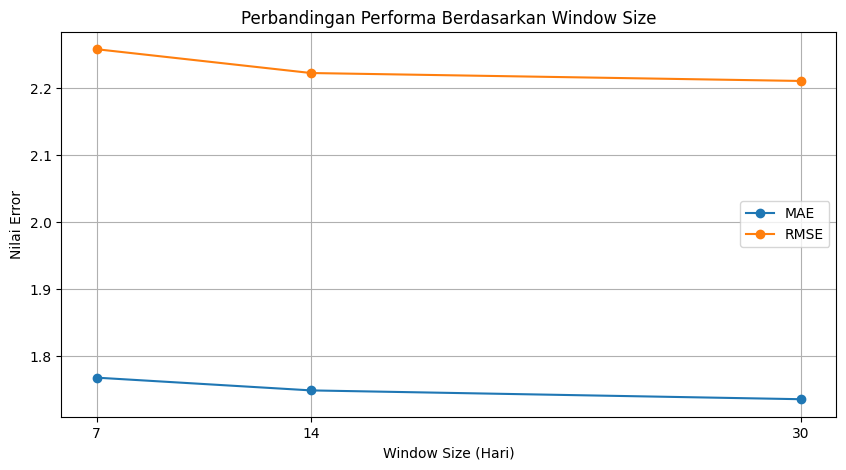

In [ ]:
#grafik perbandingan window size
plt.figure(figsize=(10, 5))
plt.plot(
    window_results_df["Window"],
    window_results_df["MAE"],
    marker="o",
    label="MAE"
)
plt.plot(
    window_results_df["Window"],
    window_results_df["RMSE"],
    marker="o",
    label="RMSE"
)

plt.xlabel("Window Size (Hari)")
plt.ylabel("Nilai Error")
plt.title("Perbandingan Performa Berdasarkan Window Size")
plt.xticks([7, 14, 30])
plt.legend()
plt.grid(True)
plt.show()

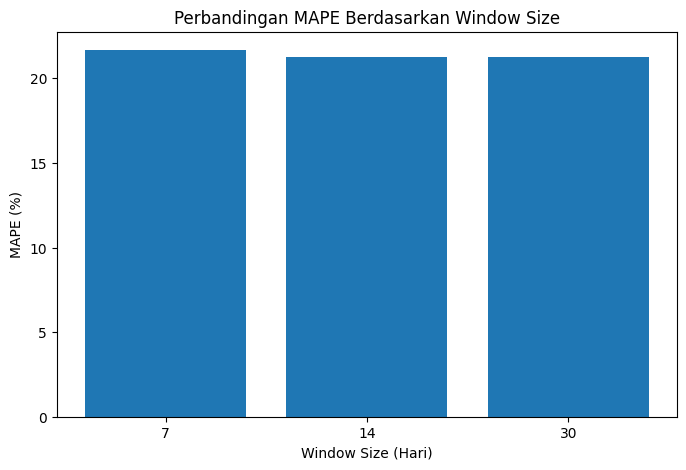

In [ ]:
#perbandingan MAPE
plt.figure(figsize=(8, 5))
plt.bar(
    window_results_df["Window"].astype(str),
    window_results_df["MAPE (%)"]
)

plt.xlabel("Window Size (Hari)")
plt.ylabel("MAPE (%)")
plt.title("Perbandingan MAPE Berdasarkan Window Size")
plt.show()

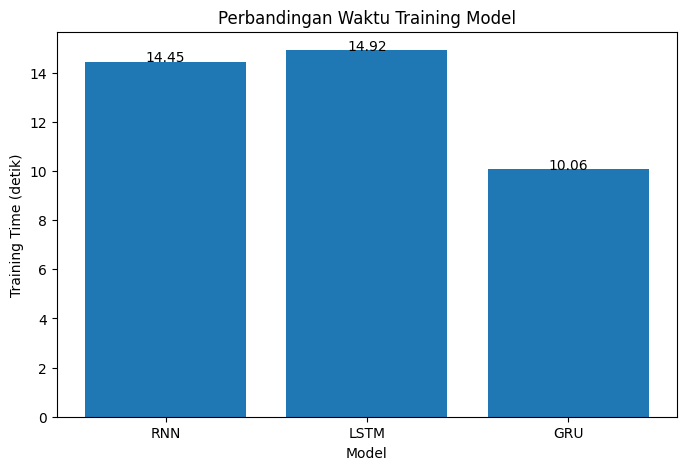

In [ ]:
#Analisis perbandingan training time antar model
plt.figure(figsize=(8,5))
plt.bar(
    results_df["Model"],
    results_df["Training Time (s)"]
)
plt.xlabel("Model")
plt.ylabel("Training Time (detik)")
plt.title("Perbandingan Waktu Training Model")
for i, v in enumerate(results_df["Training Time (s)"]):
    plt.text(i, v, f"{v:.2f}", ha='center')
plt.show()